In [1]:
import numpy as np
import matplotlib.pyplot as plt
K = 2.0 # process gain
tau = 5.0 

dt = 0.01 #must be much smaller than tau
T_end = 30.0

t = np.arange(0, T_end, dt) 

Kp=  0.5: final y = 0.5000, theory = 0.5000, steady-state error = 0.5000
Kp=    1: final y = 0.6667, theory = 0.6667, steady-state error = 0.3333
Kp=    5: final y = 0.9091, theory = 0.9091, steady-state error = 0.0909
Kp=   20: final y = 0.9756, theory = 0.9756, steady-state error = 0.0244


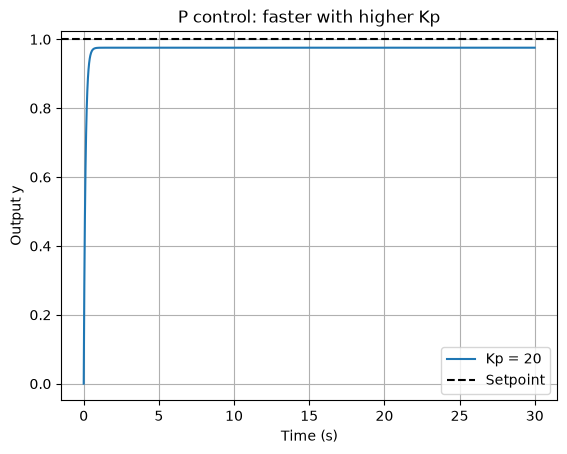

In [2]:
def simulate_p_control(Kp, r=1.0):

    y = np.zeros_like(t)
    u = np.zeros_like(t)
    for k in range(len(t) - 1):
            e = r - y[k] # 1. measure and compute error
            u[k] = Kp * e # 2. controller law
            dydt = (-y[k] + K * u[k]) / tau
            y[k + 1] = y[k] + dydt * dt # 3. plant responds
    return y, u


r = 1.0
plt.figure()
for Kp in [0.5, 1, 5, 20]:
    y, u = simulate_p_control(Kp, r)
    theory = K * Kp / (1 + K * Kp) * r
    print(f"Kp={Kp:5}: final y = {y[-1]:.4f}, theory = {theory:.4f}, "
    f"steady-state error = {r - y[-1]:.4f}")
plt.plot(t, y, label=f"Kp = {Kp}")
plt.axhline(r, color="black", linestyle="--", label="Setpoint")
plt.xlabel("Time (s)"); plt.ylabel("Output y")
plt.title("P control: faster with higher Kp")
plt.legend()
plt.grid(True)
plt.show()